# 002 — Luck, multiple testing and the deflated Sharpe ratio

Experiment pages now say whether a strategy's edge "could be luck". This notebook shows
why that question matters more than any single backtest.

**Hypotheses**

- **H1** Among many worthless strategies, the best one looks convincing: its naive p-value
  is small even though no strategy has an edge.
- **H2** The deflated Sharpe ratio (DSR) and multiple-testing corrections flag it.
- **H3** Choosing the best variant of a real strategy family (SMA trend, 1–24 months) on
  one period does not predict which variant is best on the next one.

**Signal-processing view**: each strategy is a detector, its Sharpe ratio the test
statistic. Testing N detectors on the same noise and keeping the maximum raises the
false-alarm probability from α to about 1 − (1 − α)^N.

**Data**: S&P 500 total return (`^SP500TR`, USD) since 1990, cash at the T-bill rate
(`^IRX`), costs 5 bps + 1 USD per order on 10,000.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from fin.backtest import run_backtest
from fin.backtest.compare import active_returns
from fin.backtest.runner import backtest_config, load_config
from fin.data import load_market_data
from fin.plotting import SERIES, use_style
from fin.stats import (
    compare_returns,
    expected_max_sharpe,
    probabilistic_sharpe_ratio,
)
from fin.strategy import discover

use_style()
pd.set_option("display.float_format", "{:.3f}".format)

TICKER = "^SP500TR"
cfg = backtest_config(load_config("../configs/sp500_timing.yaml"))
md = load_market_data([TICKER], currency="USD")
S = discover()
bench = run_backtest(S["buy_and_hold"](weights={TICKER: 1.0}), md, cfg)
r_bench = active_returns(bench)
rf = cfg.cash_rate.reindex(r_bench.index).ffill().fillna(0) / 252
f"{r_bench.index[0].date()} → {r_bench.index[-1].date()}, {len(r_bench)} days"

'1990-01-03 → 2026-10-23, 9270 days'

## 1. Monkeys with a calendar (H1, H2)

500 strategies that decide at random, each month, to be invested (80% of the time) or in
cash. None of them can have an edge: their decisions ignore all data. Simplified simulation:
no trading costs, monthly decisions applied to the next month's daily returns.

In [2]:
rng = np.random.default_rng(42)
months = r_bench.index.to_period("M")
unique_months = months.unique()
n_monkeys = 500
invested = rng.random((n_monkeys, len(unique_months))) < 0.8
month_pos = pd.Index(unique_months).get_indexer(months)
exposure = invested[:, month_pos]  # (monkeys, days)

r = r_bench.to_numpy()
rf_np = rf.to_numpy()
monkey_returns = np.where(exposure, r, rf_np)
excess = monkey_returns - rf_np
monkey_sharpe = excess.mean(axis=1) / excess.std(axis=1, ddof=1) * np.sqrt(252)
bench_sharpe = (r - rf_np).mean() / (r - rf_np).std(ddof=1) * np.sqrt(252)

best = int(np.argmax(monkey_sharpe))
best_r = pd.Series(monkey_returns[best], index=r_bench.index)
test = compare_returns(best_r, r_bench, rf, n_boot=2000)
summary = {
    "buy & hold Sharpe": bench_sharpe,
    "median monkey Sharpe": np.median(monkey_sharpe),
    "best monkey Sharpe": monkey_sharpe[best],
    "best monkey: Sharpe gain vs B&H": test["sharpe_diff"],
    "naive p-value of that gain": test["sharpe_diff_p"],
}
summary

{'buy & hold Sharpe': np.float64(0.5126010272600778),
 'median monkey Sharpe': np.float64(0.4570826525229391),
 'best monkey Sharpe': np.float64(0.6991519856819551),
 'best monkey: Sharpe gain vs B&H': 0.18655095842187985,
 'naive p-value of that gain': 0.0385}

How many monkeys would pass a naive 5% test against buy and hold? Testing all 500 with the
bootstrap is slow, so use the bootstrap null spread from the best monkey: under H0 the
Sharpe gain is centred on 0 with roughly that standard error.

In [3]:
se = (test["sharpe_diff_ci"][1] - test["sharpe_diff_ci"][0]) / (2 * 1.96)
gains = monkey_sharpe - bench_sharpe
naive_pass = np.mean(gains / se > stats.norm.ppf(0.95))
bonferroni_pass = np.mean(gains / se > stats.norm.ppf(1 - 0.05 / n_monkeys))
sr_std = monkey_sharpe.std(ddof=1)
# Deflation: the hurdle is the Sharpe the best of 500 worthless trials reaches by luck.
luck_hurdle = bench_sharpe + expected_max_sharpe(n_monkeys, sr_std)
pd.Series(
    {
        "share passing naive 5% test": naive_pass,
        "share passing Bonferroni (5% / 500)": bonferroni_pass,
        "expected best Sharpe of 500 worthless trials": luck_hurdle,
        "observed best Sharpe": monkey_sharpe[best],
        "P(true Sharpe > B&H), ignoring the 500 trials": probabilistic_sharpe_ratio(
            best_r - rf, bench_sharpe
        ),
        "same, deflated (hurdle = expected best by luck)": probabilistic_sharpe_ratio(
            best_r - rf, luck_hurdle
        ),
    }
)

share passing naive 5% test                       0.002
share passing Bonferroni (5% / 500)               0.000
expected best Sharpe of 500 worthless trials      0.708
observed best Sharpe                              0.699
P(true Sharpe > B&H), ignoring the 500 trials     0.870
same, deflated (hurdle = expected best by luck)   0.478
dtype: float64

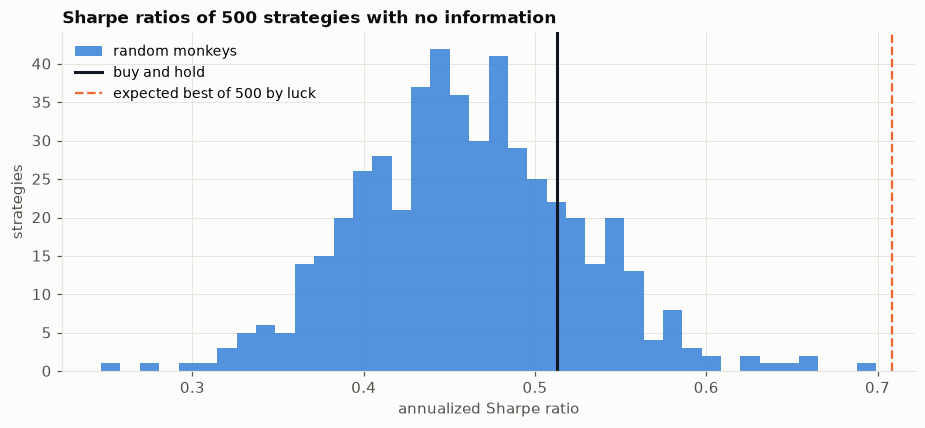

In [4]:
fig, ax = plt.subplots()
ax.hist(monkey_sharpe, bins=40, color=SERIES[0], alpha=0.8, label="random monkeys")
ax.axvline(bench_sharpe, color="#101723", lw=2, label="buy and hold")
ax.axvline(
    luck_hurdle,
    color=SERIES[1],
    lw=1.5,
    ls="--",
    label="expected best of 500 by luck",
)
ax.set_title("Sharpe ratios of 500 strategies with no information")
ax.set_xlabel("annualized Sharpe ratio")
ax.set_ylabel("strategies")
ax.legend()
plt.show()

## 2. A real strategy family: SMA trend, 1 to 24 months (H3)

Fit the lookback on 1990–2007, then check how each lookback did on 2008–today. If
in-sample rank carried information, the two Sharpe ratios would be strongly correlated.

In [5]:
split = pd.Timestamp("2008-01-01")
rows = []
for months_ in range(1, 25):
    strat = S["sma_trend"](ticker=TICKER, months=months_)
    full = run_backtest(strat, md, cfg)
    r_s = active_returns(full)
    is_, oos = r_s.loc[: split - pd.Timedelta(days=1)], r_s.loc[split:]
    b_is, b_oos = r_bench.loc[is_.index], r_bench.loc[oos.index]

    def sharpe(x, idx):
        e = x - rf.reindex(idx).fillna(0)
        return e.mean() / e.std(ddof=1) * np.sqrt(252)

    rows.append(
        {
            "months": months_,
            "IS Sharpe gain": sharpe(is_, is_.index) - sharpe(b_is, b_is.index),
            "OOS Sharpe gain": sharpe(oos, oos.index) - sharpe(b_oos, b_oos.index),
            "full Sharpe": full.metrics()["sharpe"],
            "orders": full.metrics()["n_trades"],
        }
    )
sweep = pd.DataFrame(rows).set_index("months")
sweep

,IS Sharpe gain,OOS Sharpe gain,full Sharpe,orders
months,,,,
1,-0.181,-0.308,0.262,222
2,-0.173,-0.212,0.318,182
3,-0.212,-0.021,0.399,141
4,-0.209,0.056,0.436,111
5,-0.123,0.068,0.486,99
6,-0.002,0.202,0.613,75
7,0.010,0.178,0.605,71
8,0.050,0.170,0.621,53
9,0.086,0.120,0.613,49


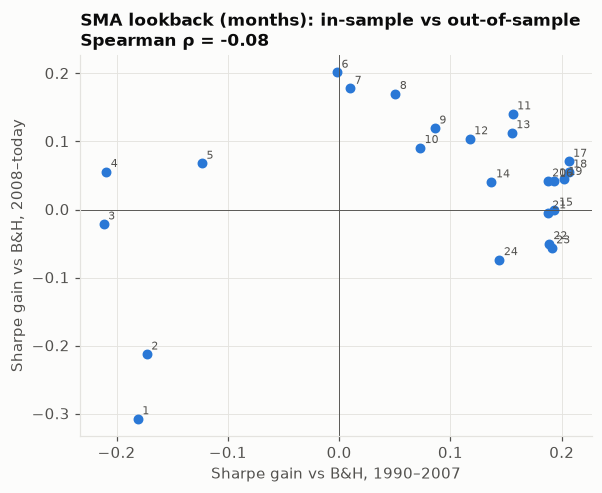

{'best lookback in-sample': 17,
 'its in-sample gain': np.float64(0.20614538289355316),
 'its out-of-sample gain': np.float64(0.07076841827925018),
 'out-of-sample rank of that lookback (1 = best)': 9,
 'Spearman rank correlation IS vs OOS': np.float64(-0.08048729144854475),
 'p-value': np.float64(0.7085057987934321)}

In [6]:
best_is = sweep["IS Sharpe gain"].idxmax()
rho = stats.spearmanr(sweep["IS Sharpe gain"], sweep["OOS Sharpe gain"])
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(sweep["IS Sharpe gain"], sweep["OOS Sharpe gain"], color=SERIES[0], s=30)
for m, row in sweep.iterrows():
    ax.annotate(str(m), (row["IS Sharpe gain"], row["OOS Sharpe gain"]), fontsize=7,
                xytext=(3, 3), textcoords="offset points", color="#52514e")
ax.axhline(0, color="#52514e", lw=0.6)
ax.axvline(0, color="#52514e", lw=0.6)
ax.set_title(f"SMA lookback (months): in-sample vs out-of-sample\nSpearman ρ = {rho.statistic:.2f}")
ax.set_xlabel("Sharpe gain vs B&H, 1990–2007")
ax.set_ylabel("Sharpe gain vs B&H, 2008–today")
plt.show()

{
    "best lookback in-sample": int(best_is),
    "its in-sample gain": sweep.loc[best_is, "IS Sharpe gain"],
    "its out-of-sample gain": sweep.loc[best_is, "OOS Sharpe gain"],
    "out-of-sample rank of that lookback (1 = best)": int(
        sweep["OOS Sharpe gain"].rank(ascending=False)[best_is]
    ),
    "Spearman rank correlation IS vs OOS": rho.statistic,
    "p-value": rho.pvalue,
}

Deflating the full-period winner of the sweep: 24 variants were tried.

In [7]:
best_full = sweep["full Sharpe"].idxmax()
r_best = active_returns(run_backtest(S["sma_trend"](ticker=TICKER, months=int(best_full)), md, cfg))
ex_best = r_best - rf.reindex(r_best.index).fillna(0)
sweep_std = sweep["full Sharpe"].std(ddof=1)
t_best = compare_returns(r_best, r_bench, rf)
pd.Series(
    {
        "best lookback (full period)": best_full,
        "Sharpe gain vs B&H": t_best["sharpe_diff"],
        "bootstrap p (as if it were the only test)": t_best["sharpe_diff_p"],
        "Bonferroni-adjusted p (x24)": min(1.0, 24 * t_best["sharpe_diff_p"]),
        "P(true Sharpe > B&H Sharpe), PSR": probabilistic_sharpe_ratio(ex_best, bench_sharpe),
        "same, hurdle raised for 24 trials (deflated)": probabilistic_sharpe_ratio(
            ex_best, bench_sharpe + expected_max_sharpe(24, sweep_std)
        ),
    }
)

best lookback (full period)                    11.000
Sharpe gain vs B&H                              0.144
bootstrap p (as if it were the only test)       0.107
Bonferroni-adjusted p (x24)                     1.000
P(true Sharpe > B&H Sharpe), PSR                0.806
same, hurdle raised for 24 trials (deflated)    0.350
dtype: float64

## 3. Conclusions

Numbers from the run on data to 2026-10-23.

**H1 (the best of many worthless strategies looks good): supported.**
- 500 random monthly in/out strategies, with no information at all. The best reaches a
  Sharpe of 0.70 vs 0.51 for buy and hold, and its naive one-sided bootstrap p-value is
  0.04: it would "pass" a standard 5% test.
- Extreme value theory predicted the best of 500 worthless trials at 0.71. The observed
  maximum (0.70) is exactly what luck produces.
- Few monkeys pass the naive test (0.2%), because random timing has a lower Sharpe on
  average (median 0.46): sitting in cash at random costs return. The point is that the
  *best* one still looks significant.

**H2 (corrections flag it): supported.**
- P(true Sharpe > buy and hold) for the best monkey: 0.87 naive, 0.48 deflated for 500
  trials. A coin flip, which is the truth.
- Bonferroni rejects every monkey.

**H3 (in-sample choice predicts out-of-sample): rejected.**
- SMA lookbacks of 1–24 months: Spearman rank correlation between the 1990–2007 and
  2008–today Sharpe gains is −0.08 (p = 0.71). In-sample rank carries no information.
- The best in-sample lookback (17 months) ranks 9th of 24 out-of-sample.
- The full-period winner (11 months, Sharpe +0.14 vs buy and hold) has bootstrap p = 0.11
  on its own, Bonferroni p = 1.0 for 24 trials, and a deflated probability of 0.35.
- What survives is a family-level pattern, not a parameter: lookbacks of roughly 6–13
  months improved the Sharpe ratio in both halves, short ones (1–4 months) hurt in both.
  That matches the trend-following literature (and the frequency-domain view of notebook
  003): too short a filter passes noise and trades it.

**Rules for this repo from now on**
- Report every variant tried, not only the winner. The experiment pages show p-values and
  the deflated Sharpe ratio for exactly this reason.
- Choose parameters by economic or signal-processing reasoning *before* looking at
  results, or by walk-forward, never by picking the best backtest.
- A Sharpe gain of 0.1–0.2 needs decades of data to be distinguishable from luck: daily
  data does not help much, because the uncertainty is about the mean, which scales with
  calendar time, not with the number of observations.